# Preprocessing and clustering PBMC 8k

This notebook uses the public 10x PBMC 8k count matrix, about 8,000 cells. It is not the Scanpy PBMC 3k tutorial.

Two calls. Each call lists its arguments so a setting can be changed in place. `prepare` returns the clustered matrix. With `show=True` it prints the QC thresholds and cell counts, then draws the QC figures and the cluster UMAP. `run` writes one name on every cluster, shows that result, and draws a dot plot of the markers that pass the expression checks.


In [1]:
%matplotlib inline
import os

os.environ.setdefault(
    "LLAMA_SERVER",
    "/tmp/llama-b12180/llama-b12180/llama-server",
)
import scanpy as sc
import annotuneagent as ata

sc.settings.verbosity = 1
sc.set_figure_params(dpi=100, frameon=False)
sc.settings.datasetdir = "/tmp/scanpy_data"


## Prepare

The file is the public PBMC 8k count matrix (`pbmc8k.h5ad`, about 8,000 cells). It is already cells, so `denoise` stays off. `batch_correction="none"` leaves the neighbor graph uncorrected. `doublet_method="none"` leaves doublet removal off. `resolution=None` uses 0.4.


AnnData object with n_obs × n_vars = 7750 × 20939
    obs: 'kit', 'tissue_ontology_term_id', 'tissue_type', 'assay_ontology_term_id', 'disease_ontology_term_id', 'cell_type_ontology_term_id', 'self_reported_ethnicity_ontology_term_id', 'development_stage_ontology_term_id', 'sex_ontology_term_id', 'donor_id', 'suspension_type', 'predicted_celltype', 'is_primary_data', 'cell_type', 'assay', 'disease', 'sex', 'tissue', 'self_reported_ethnicity', 'development_stage', 'observation_joinid'
    var: 'gene_name', 'feature_name', 'feature_reference', 'feature_biotype', 'feature_length', 'feature_type'
    obsm: 'UMAP', 'X_pca', 'X_umap'
prepare  drop genes with no counts ...


prepare  drop genes with no counts  0.0s  0 genes


prepare  QC ...


prepare  QC  0.6s  390 cells removed, 7360 remain


prepare  highly variable genes ...


prepare  highly variable genes  0.3s  2000 genes


... (8 outputs left out)

prepare  UMAP ...


prepare  UMAP  10.0s


prepare  done  19.8s  7360 cells, 11 clusters


  batch correction none

Cells
  input            7,750
  AmbiDose         off
  QC               -390 -> 7,360
all: 7,750 cells, 390 removed
  total counts: 985 to 24,773, 165 removed (162 below, 3 above)
  genes per cell: 636 to 6,255, 203 removed (201 below, 2 above)
  percent counts in top 20 genes: 8.4 to 26.3, 185 removed (0 below, 185 above)
  mitochondrial percent: 6 and 8, 187 removed
  doublets         off
  output           7,360

Genes
  input            20,939
  zero total       -0 -> 20,939

Mitochondrial genes: MT-.
Ribosomal and hemoglobin fractions are recorded, not filtered.
  mitochondrial percent cap: off

Doublets
  off


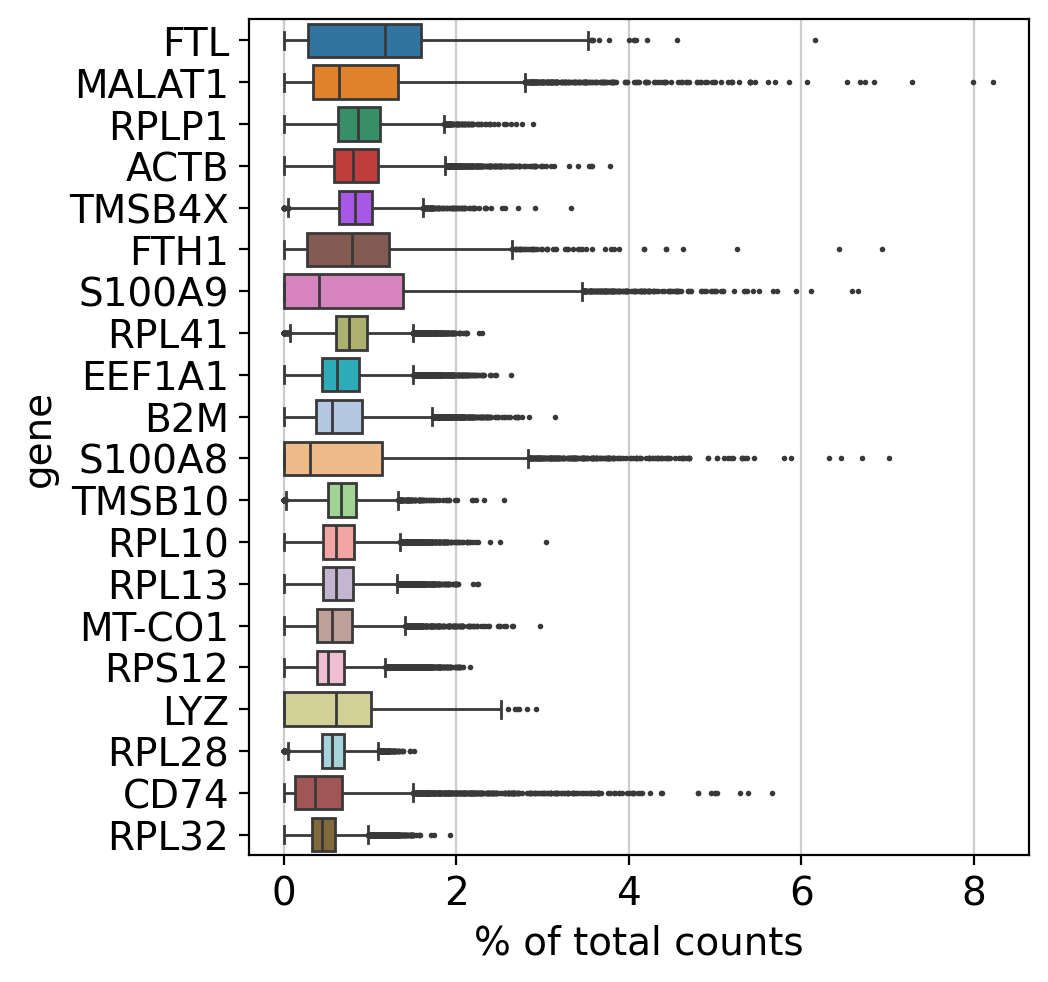

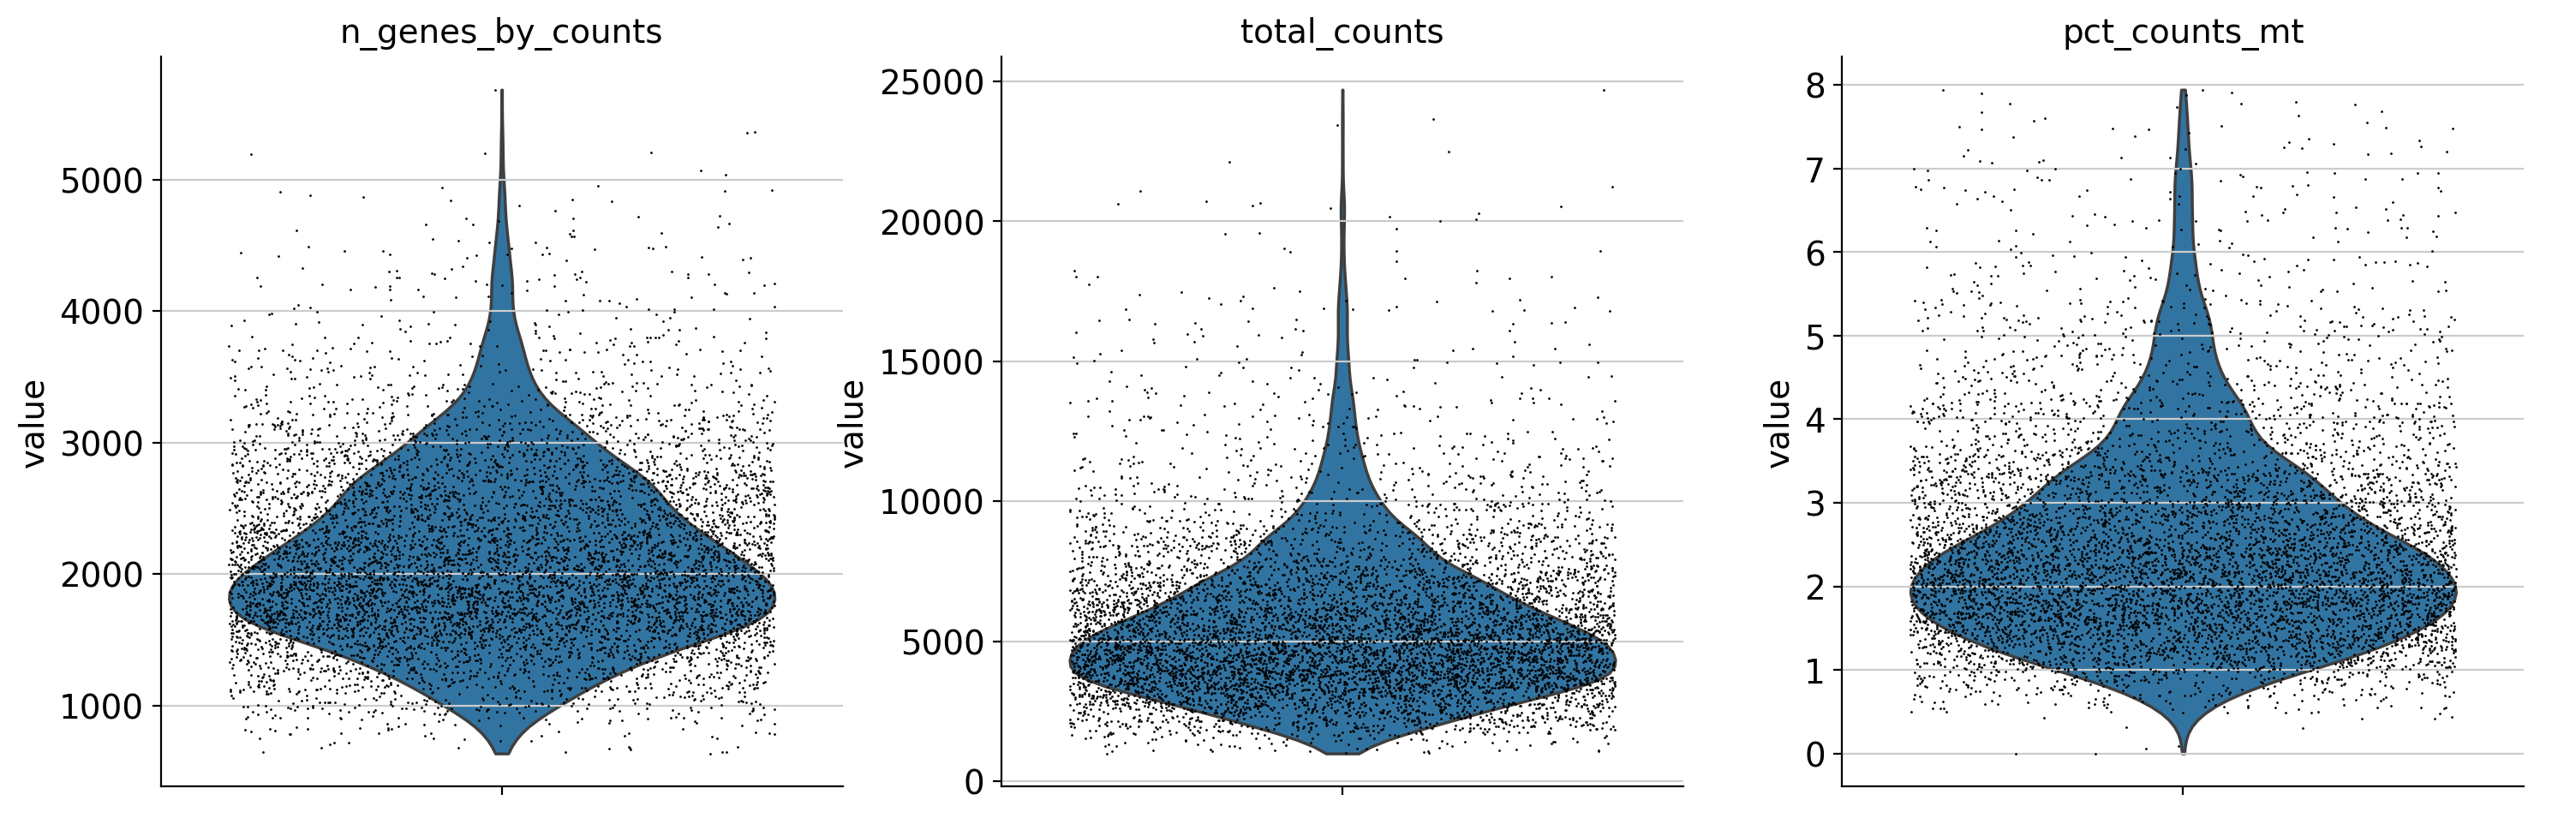

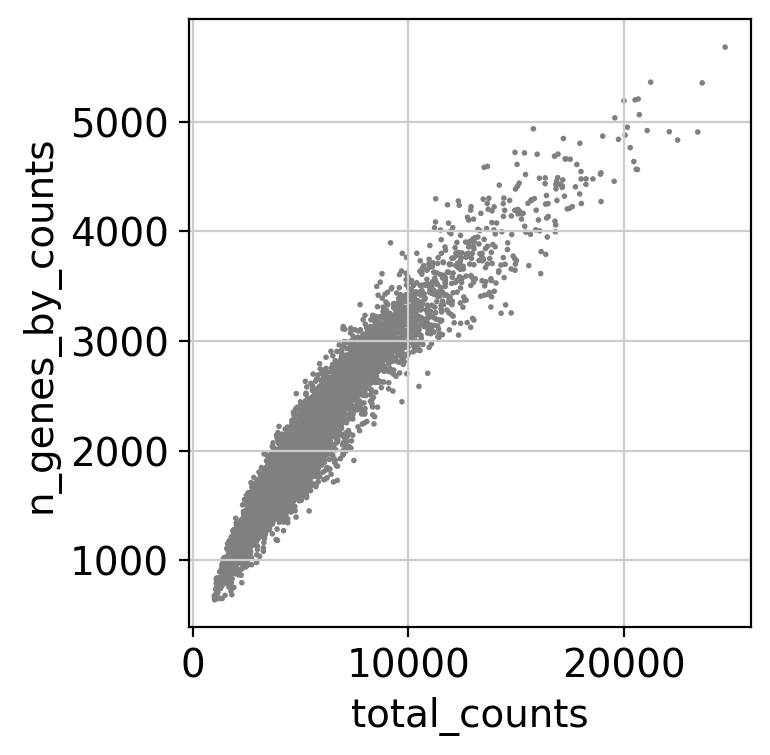

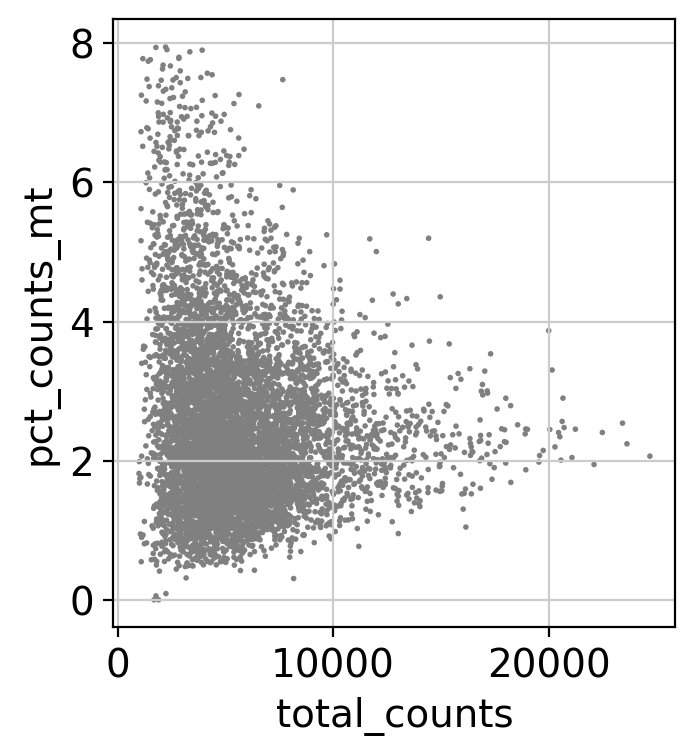

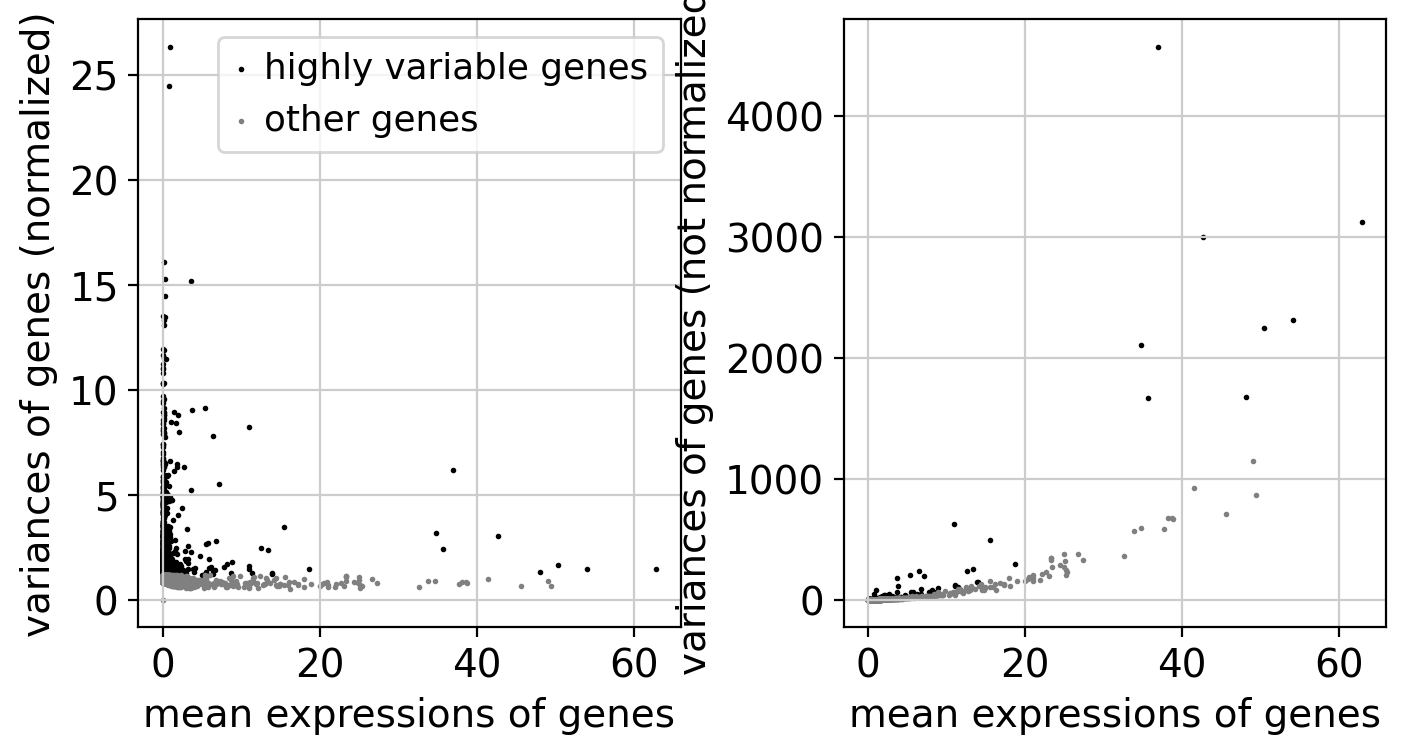

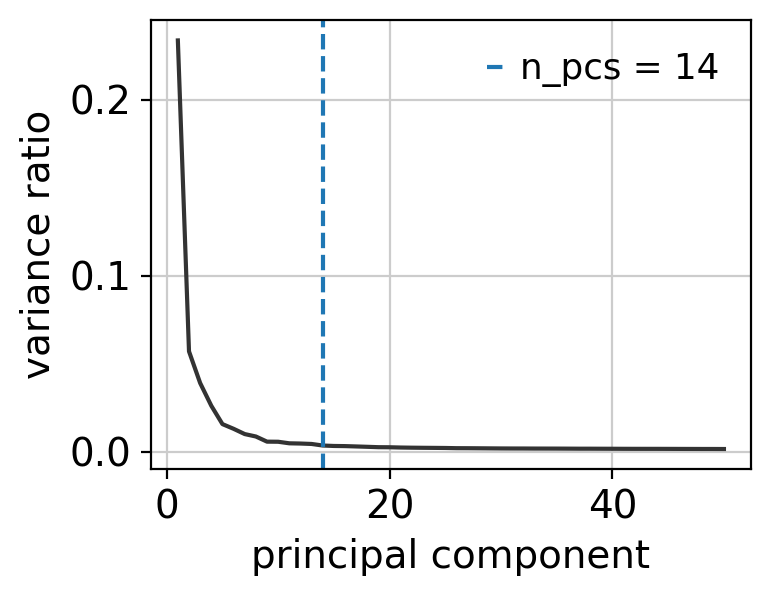

leiden
0     1728
1      257
2     2145
3      980
4      610
5      323
6      126
7      891
8      149
9      130
10      21
Name: count, dtype: int64


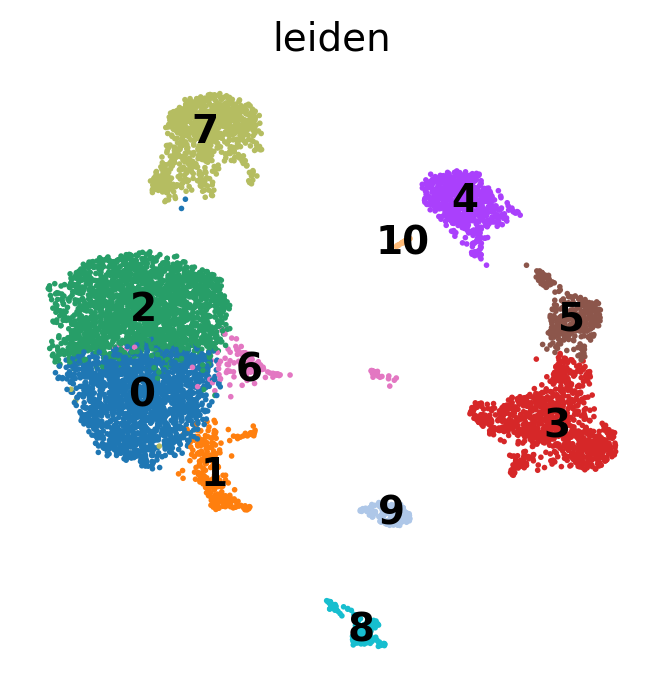

In [2]:
adata = sc.read(
    "/tmp/scanpy_data/pbmc8k.h5ad",
    backup_url="https://stacks.stanford.edu/file/cv694yk7414/pbmc8k.h5ad",
)
adata.var_names_make_unique()
print(adata)
adata = ata.prepare(
    adata,
    species="human",
    batch_key=None,
    batch_correction="none",  # none, harmony, combat, scanorama, scvi, scvi+harmony
    doublet_method="none",  # none, scrublet, solo
    doublet_chip="10k",  # 10k is 0.8% per 1,000 cells; 20k is 0.4% per 1,000
    denoise=False,
    raw=None,
    resolution=None,  # None keeps 0.4; a number is used as given
    n_pcs=None,  # None uses the variance elbow; scvi modes use 30
    n_top_genes=None,  # None keeps 2000 seurat_v3 genes
    norm="log1p",
    scfair=False,
    max_pct_mt=None,
    cluster_key="leiden",
    n_neighbors=15,
    nmads=5,
    show=True,
)


## Annotation

`tissue=None` uses the core dictionary. A page such as `"lymphoid"` adds that page. `subcluster=True` splits unresolved clusters once.


run  score markers ...


run  score markers  0.3s  8 of 11 clusters labeled


run  subcluster ...


/home/lieber/AnnoTuneAgent/src/annotuneagent/workflow.py:679: UserWarning: Ignoring svd_solver='full' and using arpack, sklearn.decomposition._pca.PCA (with sparse input) only supports dict_keys(['arpack', 'covariance_eigh']).
  sc.pp.pca(part, n_comps=n_comps, svd_solver="full")


run  subcluster  0.5s  2 clusters


run  Wilcoxon ...


... (41 outputs left out)

human, 21 cells. What cell type is this cluster?
Enriched versus other cells: GNLY (in 1.00, out 0.13, logfc 5.94); GZMB (in 1.00, out 0.11, logfc 4.65); KLRD1 (in 0.95, out 0.10, logfc 4.06); NKG7 (in 1.00, out 0.24, logfc 5.47); FGFBP2 (in 0.95, out 0.09, logfc 4.37); CD247 (in 0.95, out 0.21, logfc 4.00); PRF1 (in 0.95, out 0.14, logfc 4.35); CST7 (in 1.00, out 0.17, logfc 4.22); GZMA (in 1.00, out 0.14, logfc 3.82); SKAP1 (in 1.00, out 0.20, logfc 3.32).
Also detected: KLRF1 (in 0.67, out 0.07, logfc 3.22); CX3CR1 (in 0.71, out 0.27, logfc 2.06); FCGR3A (in 0.90, out 0.23, logfc 1.58); SPON2 (in 0.90, out 0.11, logfc 4.10); CCL5 (in 0.62, out 0.19, logfc 2.31); S100A4 (in 1.00, out 0.96, logfc -0.08); ANXA1 (in 0.86, out 0.72, logfc 0.39); KLRB1 (in 0.90, out 0.13, logfc 3.41); NCAM1 (in 0.81, out 0.03, logfc 5.02); XCL1 (in 0.57, out 0.04, logfc 3.42); SELL (in 0.62, out 0.42, logfc -0.06); CD14 (in 0.71, out 0.53, logfc 0.23); LYZ (in 1.00, out 0.73, logfc 0.86); S100A8 (in 1.00,

run  done  45.4s  11 of 11 clusters named


,cluster,cells,marker,name,ml,label,hint,reason
0,0,1728,monocyte,CD14-positive monocyte,CD14-positive monocyte,monocyte,no marker passed,no_marker_passed
1,1,257,cDC2,cDC2,cDC2,cDC2,None,evidence_agreement
2,2,2145,neutrophil,CD14-positive monocyte,CD14-positive monocyte,CD14-positive monocyte,conflict: marker neutrophil,evidence_conflict
3,3,980,"CD4-positive, alpha-beta T cell",T cell,T cell,"CD4-positive, alpha-beta T cell",None,evidence_agreement
4,4,610,None,NK cell,NK cell,NK cell,conflict: marker CD8 TEMRA cell; close marker ...,evidence_conflict
5,5,323,effector memory CD8 T cell,effector memory CD8 T cell,"CD8-positive, alpha-beta T cell",effector memory CD8 T cell,None,evidence_agreement
6,6,126,platelet,platelet,platelet,CD14-positive monocyte,conflict: marker platelet,evidence_conflict
7,7,891,CD16-positive monocyte,CD16-positive monocyte,CD16-positive monocyte,CD16-positive monocyte,None,evidence_agreement
8,8,149,None,plasma cell,plasmacytoid dendritic cell,plasmacytoid dendritic cell,conflict: name plasma cell,evidence_conflict
9,9,130,B cell,B cell,B cell,B cell,None,evidence_agreement


Doublets
  off
Dropped hypotheses
  erythrocyte: missing positive markers: HBA1, ALAS2, SLC4A1
  endothelial cell: missing positive markers: CDH5, KDR
  ILC3: missing positive markers: IL22
  mature regulatory dendritic cell: missing positive markers: CCL19
  mast cell: missing positive markers: TPSAB1, TPSB2, CPA3, MS4A2
  granulocyte-monocyte progenitor: missing positive markers: PRTN3
  megakaryocyte-erythroid progenitor: missing positive markers: PKLR
  erythroblast: missing positive markers: GYPA, ALAS2
  fibroblast: missing positive markers: DCN, LUM, COL1A1, COL1A2
  pericyte: missing positive markers: KCNJ8, ABCC9
  smooth muscle cell: missing positive markers: CNN1
  lymphatic endothelial cell: missing positive markers: CCL21, PDPN, TFF3
  arterial endothelial cell: missing positive markers: GJA5, DLL4
  venous endothelial cell: missing positive markers: ACKR1, NR2F2
  mesothelial cell: missing positive markers: WT1, KRT19, CALB2
  eosinophil: missing positive markers: CLC, SI

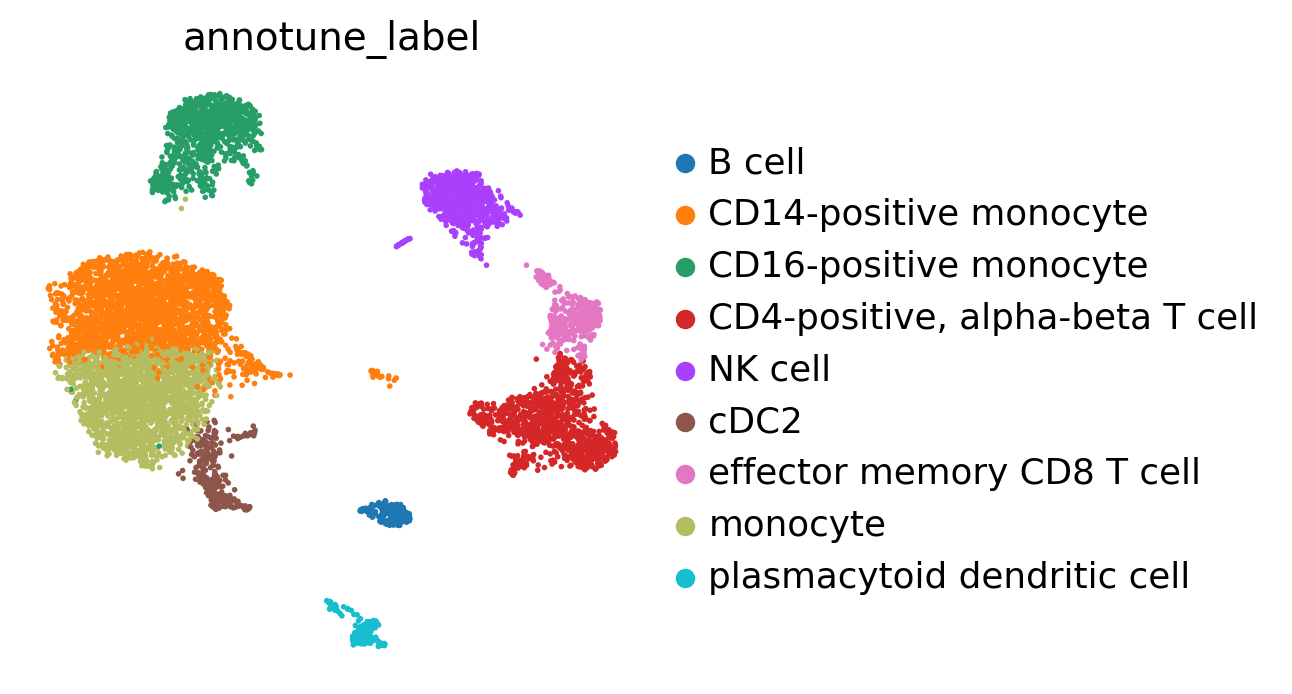

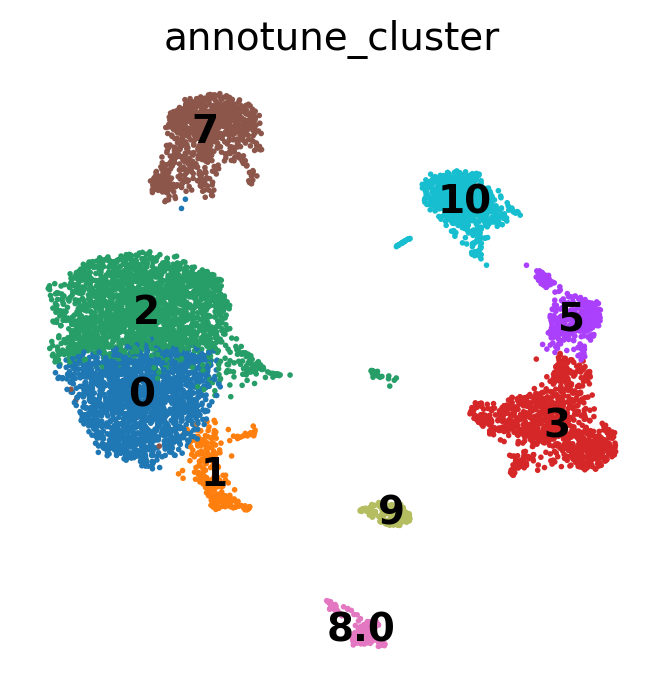

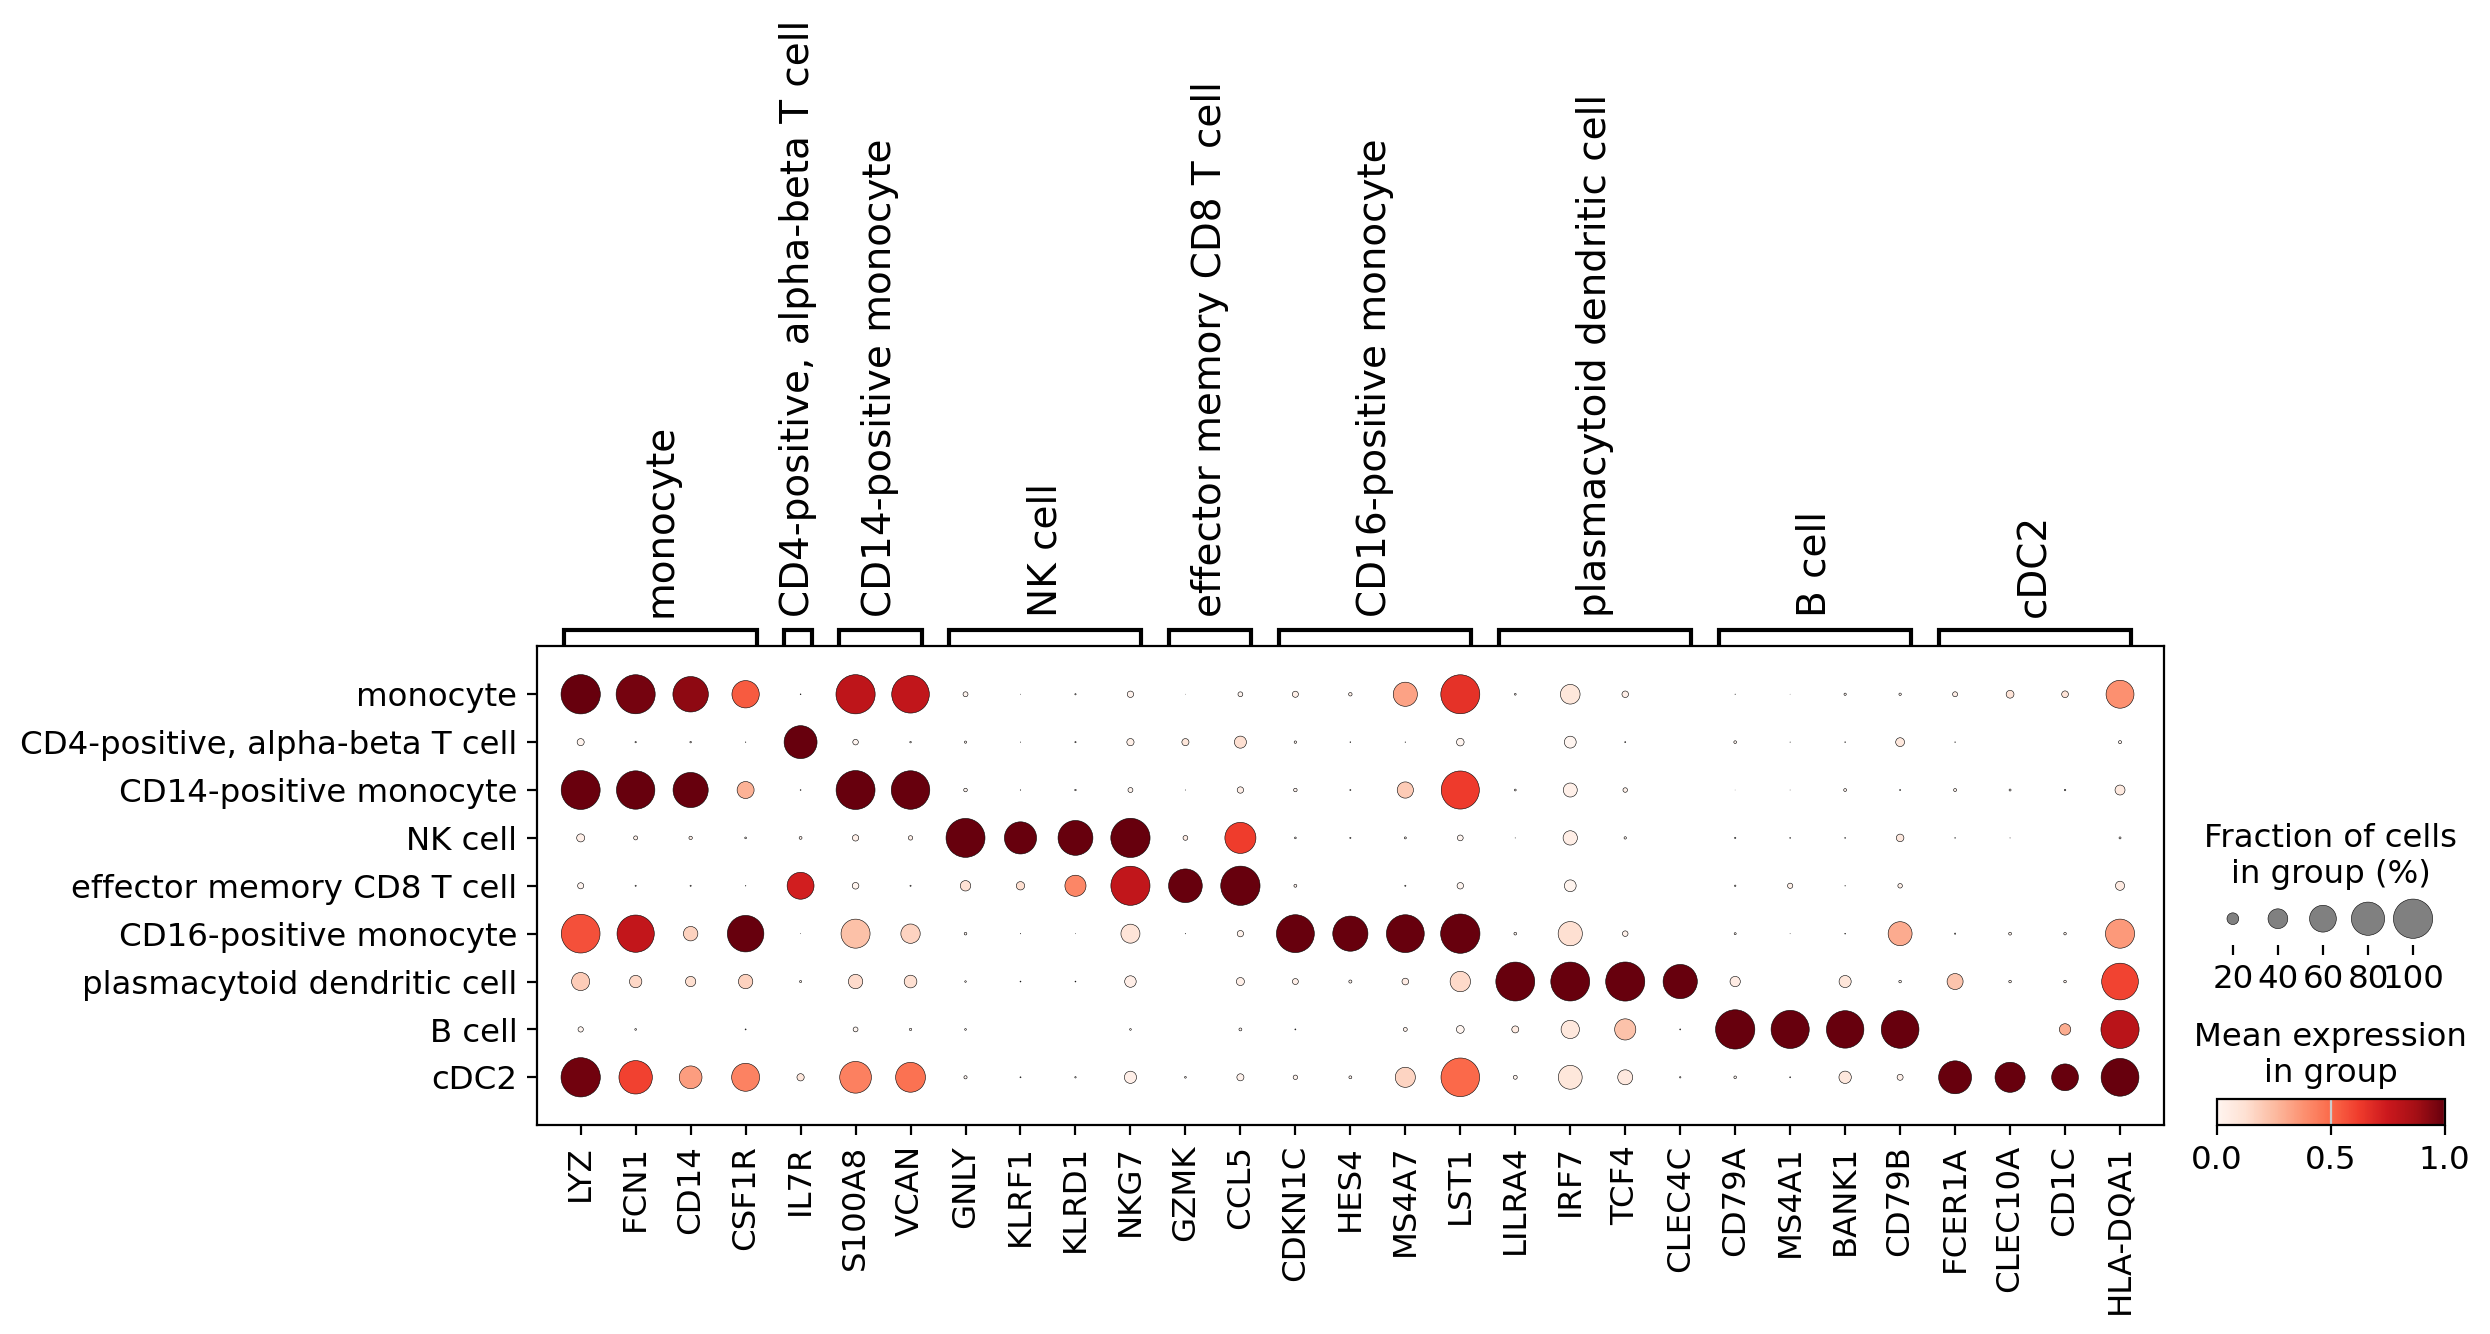

import pandas as pd
import scanpy as sc

# cluster2celltype maps each cluster id to its name.
# fine_order is the UMAP legend and the dotplot row order.
# marker_dict is the dotplot. Gene order inside a list is the column order.
cluster2celltype = {
    '0': 'monocyte',
    '1': 'cDC2',
    '2': 'CD14-positive monocyte',
    '3': 'CD4-positive, alpha-beta T cell',
    '5': 'effector memory CD8 T cell',
    '6': 'CD14-positive monocyte',
    '7': 'CD16-positive monocyte',
    '9': 'B cell',
    '10': 'NK cell',
    '4.0': 'NK cell',
    '4.1': 'NK cell',
    '4.10': 'NK cell',
    '4.2': 'NK cell',
    '4.3': 'NK cell',
    '4.4': 'NK cell',
    '4.5': 'NK cell',
    '4.6': 'NK cell',
    '4.7': 'NK cell',
    '4.8': 'NK cell',
    '4.9': 'NK cell',
    '8.0': 'plasmacytoid dendritic cell',
    '8.1': 'plasmacytoid dendritic cell',
    '8.2': 'plasmacytoid dendritic cell',
    '8.3': 'plasmacytoid dendritic cell',
    '8.4': 'plasmacytoid dendritic cell',
    '8.5': 'plasmacytoid dendri

In [3]:
from pathlib import Path

models = ata.local_models(Path("data/gguf1106"))
report = ata.run(
    adata,
    "leiden",
    species="human",
    tissue=None,
    hypotheses=None,  # None uses the built-in dictionary
    user_hypotheses=None,
    min_margin=0.15,
    models=models,
    subcluster=True,
    min_subcluster_cells=40,
    label_key="annotune_label",
    dotplot_path=None,
    show=True,
)
